![Banner](../../../../Images/Banner/03_spatial_analysis/03_06_banner_spatial_analysis_Segregation.png)



# Segregation Analysis



Residential segregation is the degree to which population groups live apart from each
other across a set of spatial units (census tracts, blocks, grid cells). It is measured,
not assumed: the same city can look integrated or segregated depending on which group
pairing, which scale, and which period you ask about, so a segregation toolkit needs more
than one number. It measures how unevenly population groups (race/ethnicity, income, age) are spread across places, and whether that pattern differs between places or changes between years.

Eight notebooks measure how unevenly groups share the Buffalo metro area, then ask where, at what scale, and whether a change between census years is real.

- **Segregation Analysis.** This notebook. The five dimensions of segregation, and a first set of indices on a multi-year tract layer.
- **Single-group segregation indices.** Evenness and exposure for one group against the rest, including dissimilarity, on Buffalo tracts.
- **Multigroup segregation indices.** Metro diversity, Theil's H, multigroup dissimilarity, and a pairwise matrix for white, Black, Hispanic, and Asian residents.
- **Local measures of segregation.** A value per tract: location quotients, local diversity, each tract's share of dissimilarity, and which local values beat chance.
- **Multiscale segregation profiles.** How far a tract's segregation extends as the neighbourhood radius grows, and a metro-wide profile.
- **Null models and simulation for segregation.** Evenness, shuffled-tract, and spatially constrained simulations, and the baseline each one sets for an index.
- **Inference for segregation indices.** Whether an index is larger than chance, whether it changed between two years, and how wide a spatial-block bootstrap interval is.
- **Segregation Over Time: Boundaries, Panels, and Decomposition.** Tract boundaries from 2000 to 2020, a harmonized panel, and a split of the decline into spatial re-sorting and a changing group mix.

Library: `geolattice.spatial_analysis.segregation` 








# Overview

Segregation analysis measures how unevenly population groups (race/ethnicity, income, age) are spread across places, and whether that pattern differs between places or changes between years. The PySAL `segregation` package covers the full workflow: global indices, local maps, scale profiles, null models, significance tests, and decomposition of differences. All the notebooks use the Sacramento 2000 census tract data (403 tracts), except the KL walkthrough, which uses Cincinnati (457 units).



## The core idea

**Dimensions.** Segregation is not one quantity. Massey and Denton (1988) described five dimensions, and most indices in the package measure one of them:

| Dimension | Question it answers | Example indices |
|---|---|---|
| Evenness | Are groups spread evenly across units? | Dissimilarity (D), Gini, Theil entropy (H), Atkinson |
| Exposure | How often do groups share units? | Isolation, Interaction |
| Concentration | How much physical space does a group occupy? | Delta, Absolute/Relative Concentration |
| Centralization | Is a group near the urban core? | Absolute/Relative Centralization |
| Clustering | Do a group's units sit next to each other? | Absolute/Relative Clustering, Spatial Proximity |

**Aspatial vs spatial.** Classic indices treat tracts as unconnected bins. That creates the checkerboard problem: a perfect checkerboard of all-Black and all-White tracts gets the same D as a city split into two halves, even though the lived experience is very different. Spatial indices fix this in one of two ways:

- **Spatially explicit indices** include distance or adjacency in the original formula (Centralization, Clustering, Spatial Proximity).
- **Generalized (spatially implicit) indices**, following Reardon and O'Sullivan, first smooth each unit's population over its neighborhood, then compute the ordinary index on the smoothed data. The neighborhood can be defined by a kernel bandwidth, a `libpysal.W` weights object, or a `pandana.Network` of travel distance.

**"Over time and space."** Space means comparing places, scales, and local patterns. Time means computing the same index for several census years and asking two questions: is the change real (inference), and why did it happen (decomposition)?



## Single-group indices (`segregation.singlegroup`)

These measure one focal group against everyone else, for example Black vs. non-Black.

Key formulas, with group count $x_i$ and total $t_i$ in unit $i$, regional group total $X$, and regional total $T$:

- Dissimilarity: $D = \tfrac12 \sum_i \left| \frac{x_i}{X} - \frac{t_i - x_i}{T - X} \right|$. This is the share of the group that would have to move for an even distribution.
- Isolation: $xPx = \sum_i \frac{x_i}{X}\cdot\frac{x_i}{t_i}$. Interaction is $1 - xPx$ for two groups.

The usage pattern is the same for every index:

```python
from segregation.singlegroup import Dissim, Gini
d = Dissim(sacramento, group_pop_var="BLACK", total_pop_var="TOT_POP")
d.statistic   # 0.488
d.data        # data used in the computation
```

Results for Black residents in Sacramento:

| Version | Gini |
|---|---|
| Aspatial | 0.636 |
| Generalized spatial, 2 km Euclidean kernel (`distance=2000`) | 0.537 |
| 2 km network distance (`network=net, decay='linear'`) | 0.585 |

Smoothing lowers the index, because segregation between adjacent tracts partly cancels out. Network distance gives a higher value than straight-line distance, because people travel on roads, not "as the crow flies." Barriers like freeways and rivers keep neighborhoods apart. `batch_compute_singlegroup()` returns all 27 single-group indices in one table.



## Multi-group indices (`segregation.multigroup`)

These measure segregation among several groups at once (White, Black, Hispanic) instead of one group against the rest.

The most widely used is Theil's information theory index $H$:

$$E = -\sum_m \pi_m \ln \pi_m, \qquad H = \sum_i \frac{t_i\,(E - E_i)}{T\,E}$$

Here $E$ is regional entropy (diversity) and $E_i$ is the entropy of unit $i$. $H = 0$ when every unit is as diverse as the region. $H = 1$ when every unit holds only one group.

Results for the three groups in Sacramento:

| Index | Value |
|---|---|
| MultiDissim | 0.425 |
| MultiInfoTheory (H) | 0.180 |
| MultiDissim, 2 km Euclidean | 0.378 |
| MultiDissim, 2 km network | 0.400 |

The spatial and network logic is the same as for single-group indices. `batch_compute_multigroup()` returns 11 indices, including diversity, Simpson's, and GlobalDistortion, which is linked to the KL approach in section 8.



## Local measures (`segregation.local`)

Global indices give one number per region. Local measures give one value per tract, so you can map where segregation happens. With $\pi_{im}$ = share of group $m$ in unit $i$:

| Measure | Formula | Reading |
|---|---|---|
| Location Quotient | $LQ_{im} = \dfrac{x_{im}/t_i}{X_m/T}$ | Greater than 1 means the group is over-represented relative to the region. Returns an n × M array, one column per group. |
| Local Diversity | $-\sum_m \pi_{im}\ln\pi_{im}$ | Higher means more mixed. |
| Local Entropy | Diversity divided by $\ln M$ | Same as diversity, scaled to 0-1. In Sacramento, 0.343 / ln 4 = 0.248. |
| Local Simpson Interaction | $\sum_m \pi_{im}(1-\pi_{im})$ | Probability that two random residents belong to different groups. |
| Local Simpson Concentration | $\sum_m \pi_{im}^2$ | Probability that they belong to the same group. It equals 1 - interaction. |
| Local Relative Centralization | Single-group, nearest-neighbor based | Ranges from -1 to +1. Shows whether the group is closer to each tract's local center than the rest of the population. |

Classes whose names start with `Multi` take a list of groups. The others take a single group and a total. These maps are the natural input for LISA or hot-spot analysis.



## Multiscalar segregation profiles (`segregation.dynamics`)

This approach comes from Reardon et al. (2008). You compute an index, widen the neighborhood radius, recompute, and repeat. The result is a curve of segregation against scale.

```python
from segregation.dynamics import compute_multiscalar_profile
prof = compute_multiscalar_profile(sacramento, segregation_index=Gini,
        group_pop_var="BLACK", total_pop_var="TOT_POP",
        distances=range(500, 5500, 500))



For Black residents in Sacramento, Gini falls from 0.636 at 0 m to 0.537 at 2 km and 0.413 at 5 km.

**Reading a profile:**

- **Steep early drop:** segregation is micro-scale. Pockets disappear once you look a little wider.
- **Flat curve:** segregation is macro-scale. Large contiguous areas stay homogeneous even at wide radii.
- **Network vs. Euclidean:** the network-based D profile falls more slowly. Travel infrastructure keeps segregation in place at larger distances.

Any of the 23 generalized indices (single or multi-group) can be profiled. The functions `batch_multiscalar_singlegroup` and `batch_multiscalar_multigroup` compute them all. For time analysis, plotting profiles for 1990, 2000, and 2010 on one chart shows whether segregation is fading at fine scales while persisting at coarse ones.



## Simulating random populations (null models)

A key point from Boisso et al. (1994) is that "no segregation" does not give an index of 0. Random allocation still produces some unevenness, especially for small groups. So you need a simulated reference distribution. The package offers three randomization schemes:

| Function | What is randomized | What is preserved | What varies |
|---|---|---|---|
| `simulate_evenness` | Each resident in each unit is drawn as the focal group with probability equal to the regional share (6.8% for Black residents) | Unit totals | Group totals vary slightly (121,457 vs. 122,022) |
| `simulate_systematic_randomization` | Each group member is placed in a unit with probability equal to the unit's share of total population | Group totals | Unit totals vary |
| `simulate_person_permutation` | Individuals are shuffled among units | Both group totals and unit totals | Neither |

The notebook's summary is: evenness includes group-level variation, systematic includes unit-level variation, and permutation includes neither. `simulate_null(seg_class, sim_func)` runs these in parallel to build the null distribution. For Sacramento, all three give similar distributions that are not centered on zero. The schemes can diverge when minority groups are very small or very unbalanced.



## Single-value and comparative inference (`segregation.inference`)

### Single-value test: is this place segregated at all?

`SingleValueTest(index, null_approach=...)` compares the observed index with a simulated null distribution.

- **Evenness null.** Hispanic D = 0.322, while the null mean is about 0.016, so p ≈ 0 and segregation is real. This null fits evenness indices.
- **Bootstrap.** This simulates the sampling distribution of D itself, then tests it against 0 or against the evenness null mean. Both give the same conclusion here.
- **Geographic permutation.** This shuffles where whole tracts sit, keeping their contents. It is the right test for spatial indices. Relative Concentration = 0.126 with p = 0.54, so it is not significant. The Hispanic population is uneven across tracts, but not unusually concentrated in space.
- **`even_permutation`.** This generates an evenness population first, then permutes it geographically.

The point is to match the null to the dimension you are measuring.

### Two-value test: are two places or two years different?

`TwoValueTest(index1, index2, null_approach=...)` handles both space (City A vs. City B) and time (Year 1 vs. Year 2). The notebook splits Sacramento into west (D = 0.277) and east (D = 0.258):

- **`random_label`** (Rey & Sastré-Gutiérrez, 2010) shuffles units between the two contexts and builds a distribution of differences. p = 0.43.
- **`bootstrap`** (Davidson, 2009) bootstraps each index and runs a means test. p = 0.43. Use it only for aspatial indices: it ignores spatial autocorrelation, and resampling duplicates units, which breaks the geometry.

Conclusion: the 0.02 gap is not significant. For time comparisons, the same tract geography must be used in both years, which means harmonizing boundaries first (for example with PySAL's `geosnap`).



## Decomposition: why do two values differ?

`DecomposeSegregation(index1, index2, counterfactual_approach=...)` follows Rey et al., "Comparative Spatial Segregation Analytics." It uses a Shapley decomposition to split the difference between two indices into two parts:

$$S_A - S_B = c_s + c_a$$

- **$c_a$ (attribute component):** the part due to different population composition, such as how large the group is and how its tract shares are distributed.
- **$c_s$ (spatial component):** the part due to how those compositions are arranged in space.

The method builds counterfactuals: City A's spatial layout with City B's composition distribution, matched by quantiles (CDFs), and the reverse. It then averages the effects. There are three counterfactual approaches: `composition` (default), `share`, and `dual_composition`.

Sacramento, Black Gini, west minus east:

| | Difference | $c_s$ | $c_a$ |
|---|---|---|---|
| Composition approach | -0.150 | -0.004 | -0.146 |
| Share approach | -0.150 | -0.048 | -0.101 |
| Relative Concentration | -0.074 | +0.035 | -0.108 |

Almost all of the Gini gap comes from attributes, not spatial arrangement. For the spatial index, the spatial component carries more weight and points the opposite way. Use `.plot(plot_type="cdfs")` or `"maps"` to see the counterfactuals.

For time analysis, this is the most useful tool. It tells you whether segregation rose because the group's composition changed (growth, immigration) or because people sorted differently in space.



## `kl_divergence_profile`: the Olteanu et al. (2019) multiscalar view

This is a different multiscalar method, based on Olteanu et al., "Segregation through the multiscalar lens," PNAS. For every unit, it grows a neighborhood outward one nearest neighbor at a time and measures how far the accumulated population mix is from the city-wide mix, using Kullback-Leibler divergence:

$$d_{KL}(q \,\|\, r) = \sum_{m=1}^{k} q_m \ln\frac{q_m}{r_m}$$

Here $q$ is the cumulative group proportions around the focal unit and $r$ is the regional proportions.

**Algorithm:**

1. Compute centroids and a full pairwise distance matrix with `pdist`. The metric is configurable.
2. For each unit, sort all units by distance and take cumulative group counts.
3. Convert to proportions $q$ and compute divergence from $r$ using `scipy.special.rel_entr`. This function treats $0\ln 0 = 0$, which is why it is used instead of `kl_div`.
4. Return a row for each step with four columns: `observation`, `distance`, `divergence`, `population_covered`.

The output is large: n² rows (457² = 208,849 for Cincinnati).

**Reading the profile:**

- At distance 0, divergence is local segregation: how unlike the city that unit is.
- Divergence always converges to 0 once the whole city is included.
- How far you must go before divergence becomes small is the "segregation scale" for that location. Large distances mean the unit sits inside a big homogeneous area.
- Taking `.groupby('observation').first()` gives a local divergence map.

The "invalid value in divide" warnings in the notebook come from units with zero population and are harmless.

Inputs can be a GeoDataFrame containing only count columns plus geometry, or separate populations and coordinates objects. Use raw counts, not percentages.



## Putting it together for space and time

1. **Harmonize geography** across census years so units are comparable.
2. **Global indices** for each year, single and multi-group, aspatial and spatial (network if possible).
3. **Single-value test** for each year: is segregation above what random allocation gives?
4. **Two-value test** between Year 1 and Year 2, or between cities: is the change real?
5. **Decomposition** of the change: composition shift or spatial re-sorting?
6. **Multiscalar or KL profiles** for each year: did segregation shift between micro and macro scale?
7. **Local maps** (LQ, entropy, local KL) for each year: where did it intensify or ease?

This pipeline would fit well alongside your spatial causal package. Local segregation surfaces can serve as exposures or confounders in a spatial causal model of health outcomes.



**Sources:**
- [Single-group Segregation Indices](https://pysal.org/segregation/notebooks/01_singlegroup_indices.html)
- [Multi-group Segregation Indices](https://pysal.org/segregation/notebooks/02_multigroup_indices.html)
- [Local Measures of Segregation](https://pysal.org/segregation/notebooks/03_local_indices.html)
- [Multiscalar Segregation Profiles](https://pysal.org/segregation/notebooks/04_multiscalar_example.html)
- [Simulating Population Groups Distributed Randomly in Space](https://pysal.org/segregation/notebooks/05_simulating_random_population.html)
- [Single Value and Comparative Inference](https://pysal.org/segregation/notebooks/06_inference.html)
- [Segregation Index Decomposition](https://pysal.org/segregation/notebooks/07_decomposition_example.html)
- [kl_divergence_profile walkthrough](https://pysal.org/segregation/notebooks/kl_divergence_profile_walkthrough.html)


`geolattice.spatial_analysis.segregation` is a lighter, faster, time-series-aware alternative
to PySAL's `segregation` package, built around three gaps in it:

1. **Scale.** PySAL's spatial (KL-divergence) profile builds a dense n x n distance
   matrix and an n^2-row table -- it runs out of memory well before a few thousand units.
   This module's `multiscale.compute_profile` uses a `scipy.spatial.cKDTree` and never
   materializes either.
2. **Time.** PySAL only ever compares two values at a time. This module accepts a whole
   panel of years, harmonizes boundaries across them (areal or dasymetric interpolation),
   tests the resulting trend (Mann-Kendall), and chains the spatial-vs-composition
   decomposition across every consecutive pair of periods instead of just one.
3. **Inference.** PySAL's bootstrap resamples individual units, which is only valid if
   neighboring units are independent -- exactly what spatial autocorrelation violates.
   This module resamples whole spatial blocks instead, and adds permutation significance
   with false-discovery-rate correction for local (LISA-style) maps.

This notebook is a hands-on tour of the whole module on one synthetic city. Every single-
and multi-group index it computes is checked in `tests/test_segregation.py` against
PySAL's own `segregation` package values, so the numbers below are not just internally
consistent -- they agree with the field's existing reference implementation wherever the
two overlap.






## Setup and the synthetic study city

The data below (`Data/03_spatial_analysis/data_segregation/make_data.py`) is a fictional ~14 km x 14 km city
with four population groups across three census years (2000, 2010, 2020) on one shared
set of 92 Voronoi "tracts", plus a fourth, older year (1990) deliberately built on a
*different*, coarser set of 18 tract boundaries -- the real-world problem every multi-
decade segregation panel has, since census geography gets redrawn almost every decade.
A built-up-intensity raster is also provided, for the dasymetric boundary-harmonization
example later on.

The city's demographic pattern is not random: it starts as a sharp east/west divide in
1990 and partially integrates by 2020, so every index, map, trend test, and decomposition
below has a real, interpretable signal to recover.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
# Areal interpolation can warn on zero-area slivers; geolattice already silences the expected case.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tract panels
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares and scale masks
import pandas as pd  # tabular display of results

# Hide UserWarnings so notebook output stays readable.
warnings.filterwarnings("ignore", category=UserWarning)  # run this analysis or plotting step

# ===================================================================
# Setup for the segregation overview notebook.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation,
# and import geolattice.spatial_analysis.segregation as seg.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Synthetic multi-year tract data for the segregation chapter.
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation"  # define DATA

# Segregation indices, locals, profiles, harmonisation, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

GROUPS = ["white", "black", "hispanic", "asian"]  # race/ethnicity count columns
# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})  # run this analysis or plotting step
print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__)  # run this analysis or plotting step


repo: /media/zia207/SSD/GitHub/GeoLattice
data: /media/zia207/SSD/GitHub/GeoLattice/data/data_segregation
geopandas 1.1.2


92 tracts per year (2000/2010/2020); 18 coarse tracts in 1990
total population by year: {2000: 275452, 2010: 314166, 2020: 329822}


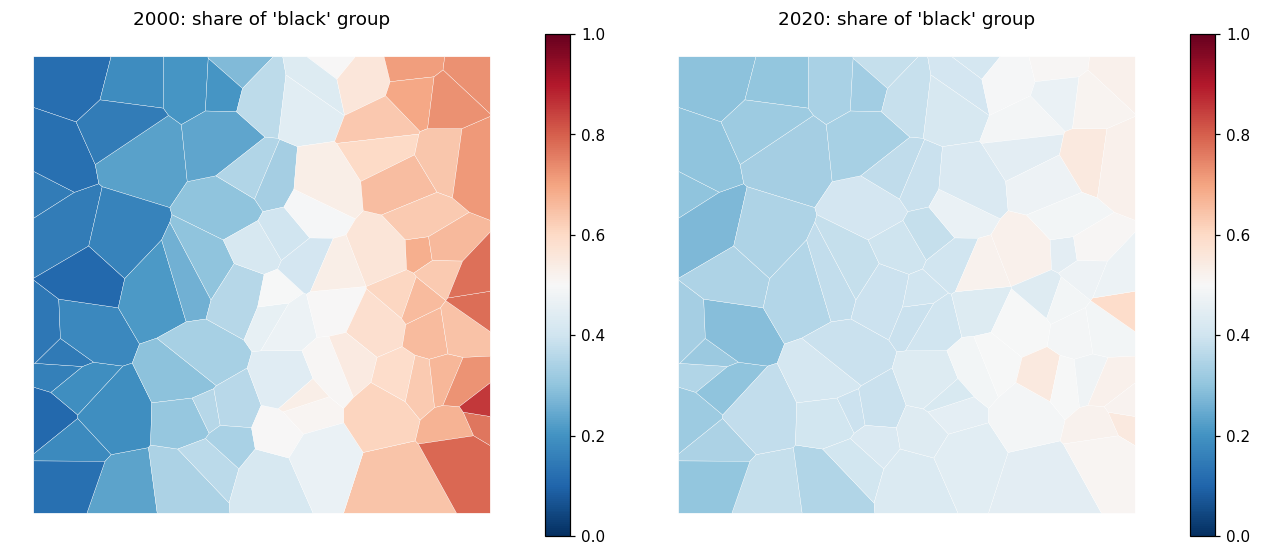

In [2]:
# ===================================================================
# Load the shared-boundary years plus coarse 1990 tracts, then map the
# black population share in 2000 vs 2020 as a first look at the pattern.
# ===================================================================

# Three years that already share one boundary set.
tracts = {year: gpd.read_file(DATA / f"tracts_{year}.geojson") for year in (2000, 2010, 2020)}  # define tracts
# 1990 uses coarser boundaries and needs harmonising before panel work.
tracts_1990_coarse = gpd.read_file(DATA / "tracts_1990_coarse.geojson")  # define tracts_1990_coarse
print(  # run this analysis or plotting step
    f"{len(tracts[2020])} tracts per year (2000/2010/2020); "  # field in the summary row
    f"{len(tracts_1990_coarse)} coarse tracts in 1990"  # run this analysis or plotting step
)
print(  # run this analysis or plotting step
    "total population by year:",  # field in the summary row
    {y: int(g[GROUPS].sum().sum()) for y, g in tracts.items()},  # run this analysis or plotting step
)

# Side-by-side choropleths of the black share (the pattern later indices summarise).
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # run this analysis or plotting step
for ax, year in zip(axes, (2000, 2020)):  # iterate paired sequences together
    g = tracts[year]  # define g
    share = g["black"] / g[GROUPS].sum(axis=1)  # tract share of the black group
    g.assign(_share=share).plot(  # draw geometries or a series on the axes
        column="_share", cmap="RdBu_r", vmin=0, vmax=1,  # define column
        legend=True, ax=ax, edgecolor="white", linewidth=0.2,  # define legend
    )
    ax.set_title(f"{year}: share of 'black' group")  # set labels, title, or axis limits
    ax.set_axis_off()  # run this analysis or plotting step
plt.tight_layout()  # run this analysis or plotting step
plt.show()  # run this analysis or plotting step



## Region-wide indices, with a spatial-block bootstrap confidence interval

`seg.compute()` is the single entry point: name an index, name the group columns, and
optionally ask for a confidence interval. `ci=True` calls
`inference.spatial_block_bootstrap` under the hood, which resamples whole *spatial
blocks* of tracts together (so spatially correlated neighbors move together in each
replicate) rather than resampling individual tracts as if they were independent -- the
assumption a plain unit-level bootstrap makes, and spatial autocorrelation violates.

- **Dissimilarity** (`"dissimilarity"`): the share of either group that would have to
  move for every tract to match the city's overall composition. 0 = no segregation,
  1 = complete segregation.
- **Gini** (`"gini"`): like dissimilarity, but weighted so larger tracts count more.
- **Theil's H** (`"theil_h"`): the multigroup information-theory index -- how much of
  the city's overall racial/ethnic diversity is "explained away" by which tract people
  live in, across all four groups at once (not just white/black).






In [3]:
# ===================================================================
# Region-wide indices for 2020 with spatial-block-bootstrap CIs.
# n_blocks=8 keeps neighbouring tracts' dependence in the resampling.
# ===================================================================

# Dissimilarity and Gini for the white-black pair.
for index_name, pair in [("dissimilarity", ("white", "black")), ("gini", ("white", "black"))]:  # loop over group pairs
    result = seg.compute(  # define result
        tracts[2020],
        index=index_name,  # define index
        groups=list(pair),  # define groups
        ci=True,  # define ci
        n_boot=299,  # bootstrap replicates
        n_blocks=8,  # spatial blocks for dependence-preserving CI
        seed=0,  # define seed
    )
    print(result.summary())  # run this analysis or plotting step

# Theil's H uses all four groups at once, not just one pair.
theil_result = seg.compute(  # define theil_result
    tracts[2020],
    index="theil_h",  # define index
    groups=GROUPS,  # define groups
    ci=True,  # define ci
    n_boot=299,  # define n_boot
    n_blocks=8,  # define n_blocks
    seed=0,  # define seed
)
print(theil_result.summary())  # run this analysis or plotting step


dissimilarity(white, black) = 0.1383 (95% CI [0.0866, 0.1749])


gini(white, black) = 0.1881 (95% CI [0.1247, 0.2213])


theil_h(white, black, hispanic, asian) = 0.0187 (95% CI [0.0117, 0.0238])


## Local measures and permutation significance (a LISA-style map)

A single region-wide number hides *where* segregation is concentrated. `local_quotient`
computes each tract's location quotient for one group: `LQ = (tract's share of the
group) / (city-wide share of the group)`. `LQ > 1` means that group is over-represented
in that tract.

But some of that variation is just noise from small tract populations. `local_significance`
tests every tract's LQ against an "evenness" null (each tract's population redrawn from
the city-wide proportions, keeping its own total fixed) with 999 permutations, then
applies Benjamini-Hochberg false-discovery-rate correction across all 92 simultaneous
tests -- the same multiple-comparisons problem a local Moran's I cluster map has. Only
tracts whose LQ survives that correction are shown as significant.






       statistic    p_value
count  92.000000  92.000000
mean    0.998677   0.523891
std     0.177997   0.480229
min     0.651717   0.001000
25%     0.893910   0.001000
50%     0.982837   0.780500
75%     1.157353   1.000000
max     1.403351   1.000000

37 of 92 tracts are significant at FDR 0.05


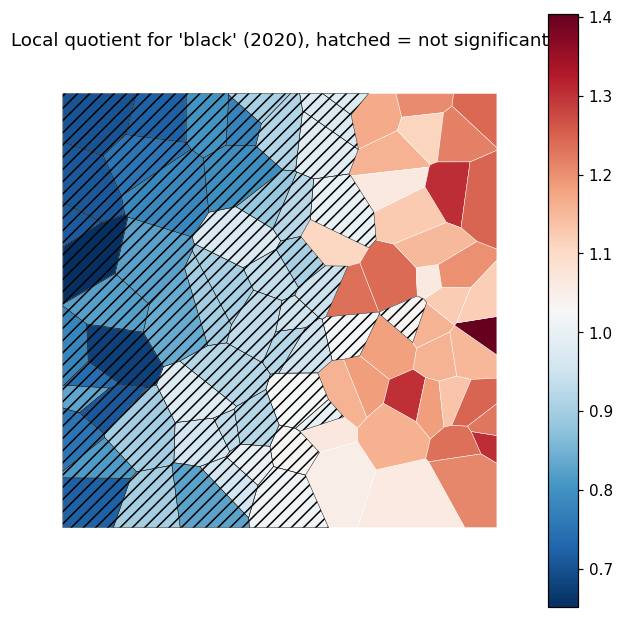

In [4]:
# ===================================================================
# Local quotient for 'black' with FDR-corrected permutation significance,
# then map LQ and hatch tracts that fail FDR 0.05.
# ===================================================================

# Permute each tract's 4-group composition under the city proportions.
sig = seg.local_significance(  # define sig
    tracts[2020],
    GROUPS,
    seg.local_quotient,
    group="black",  # define group
    permutations=999,  # define permutations
    alpha=0.05,  # define alpha
    seed=0,  # define seed
)
print(sig.describe())  # run this analysis or plotting step
print(f"\n{sig.significant_fdr.sum()} of {len(sig)} tracts are significant at FDR 0.05")  # run this analysis or plotting step

# Colour by LQ; hatch tracts that did not survive FDR correction.
ax = seg.plot_local_map(  # axes handle for drawing
    tracts[2020],
    sig["statistic"],
    significant=sig["significant_fdr"],  # define significant
    title="Local quotient for 'black' (2020), hatched = not significant",  # define title
    cmap="RdBu_r",  # define cmap
)
plt.show()  # run this analysis or plotting step


## The multiscale segregation profile (fast, KD-tree based)

How far does a tract's segregation reach before it blends into the city's overall
composition? `multiscale.compute_profile` pools each tract's composition within growing
radii and measures its KL divergence from the city-wide composition at each one --
Reardon et al.'s "spatial segregation profile" idea, but computed by querying a
`scipy.spatial.cKDTree` for each tract's own (typically small) neighbor list, never
building the dense `n x n` distance matrix PySAL's own implementation does. That is the
difference between this running in milliseconds on 92 tracts (and staying linear-ish out
to thousands) and running out of memory.

Three compact, mappable outputs come out of the profile instead of a raw curve per tract:

- **`segregation_scale`**: the radius at which a tract's divergence first drops below a
  threshold (small = a short-range, very local pattern; large/`inf` = persists broadly).
- **`auc`**: area under the divergence-vs-radius curve (one number for "how segregated,
  integrated over scale").
- **`distortion`**: the fraction of a tract's own-unit divergence still left at the
  largest radius queried (near 0 = decays away quickly with pooling; near 1 = barely
  decays over the measured range).






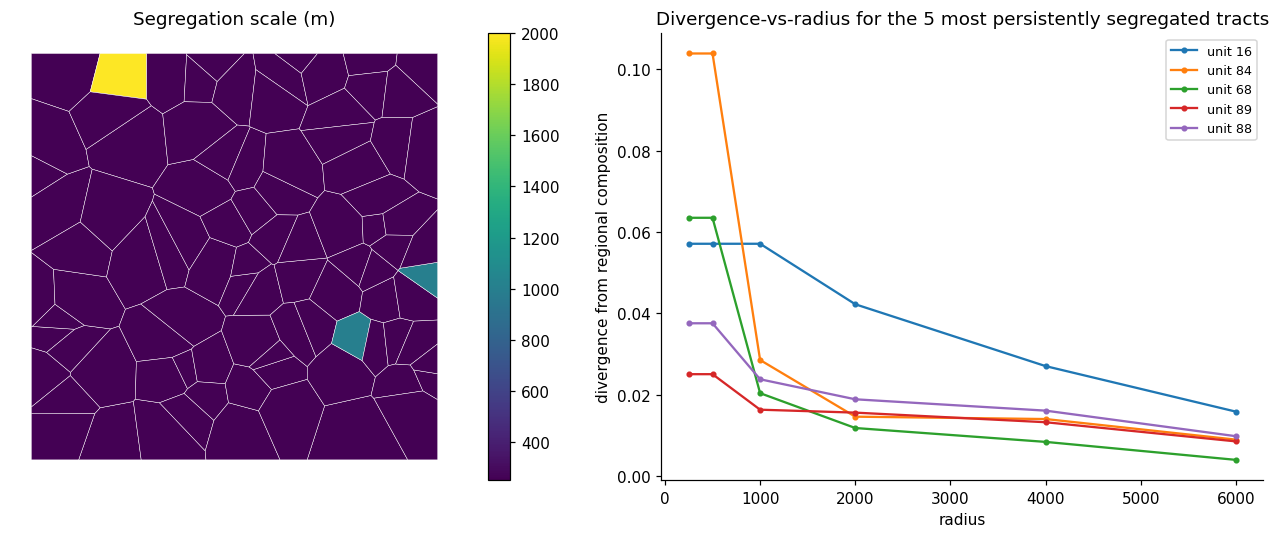

In [5]:
# ===================================================================
# Multiscale KL divergence profiles and segregation-scale map.
# Radii span from a single tract (~250 m) to most of the city (~6000 m).
# ===================================================================

profile = seg.compute_profile(  # define profile
    tracts[2020],
    GROUPS,
    radii=[250, 500, 1000, 2000, 4000, 6000],  # metres
    divergence="kl",  # Reardon KL divergence
    scale_threshold=0.05,  # converge when divergence falls below this
)
# Cap non-finite scales at the largest radius for mapping.
tracts[2020]["segregation_scale"] = np.where(  # assign a derived column or cell
    np.isfinite(profile.segregation_scale),  # run this analysis or plotting step
    profile.segregation_scale,
    6000.0,
)
tracts[2020]["profile_auc"] = profile.auc  # area under the divergence-radius curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # run this analysis or plotting step
seg.plot_local_map(  # run this analysis or plotting step
    tracts[2020], tracts[2020]["segregation_scale"], ax=axes[0],
    title="Segregation scale (m)", cmap="viridis",  # define title
)
seg.plot_profile(profile, ax=axes[1])  # highlight the most persistent tracts
axes[1].set_title("Divergence-vs-radius for the 5 most persistently segregated tracts")  # set labels, title, or axis limits
plt.tight_layout()  # run this analysis or plotting step
plt.show()  # run this analysis or plotting step


## Spatial neighborhoods: pooling composition across nearby tracts

A tract's *own* population can be small enough that its composition is noisy. Pooling in
nearby tracts first -- building a "generalized spatial" version of any local measure --
is what the `neighborhoods` module is for. `kernel_weights` gives every tract within a
bandwidth a smooth (Gaussian) or hard-cutoff weight; `knn_weights` instead uses libpysal's
k-nearest-neighbor graph. Pass either into any `local` function's `neighborhood=` argument.






std(LQ) unpooled: 0.177   std(LQ) kernel-pooled: 0.164


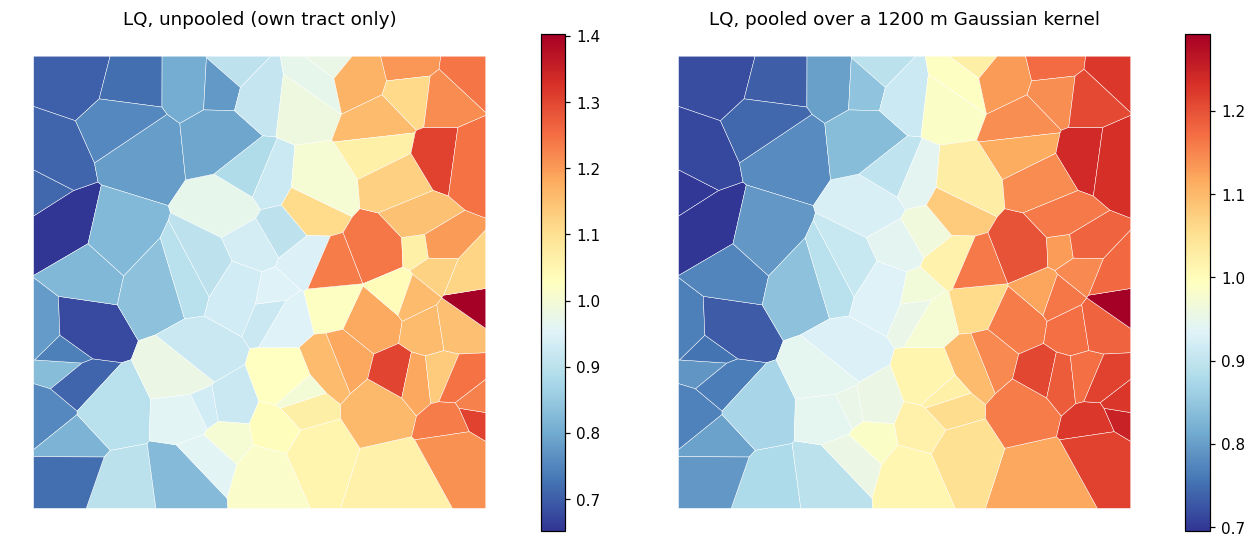

In [6]:
# ===================================================================
# Compare unpooled LQ with LQ pooled over a ~1200 m Gaussian kernel.
# knn_weights is built as the alternative neighbourhood constructor.
# ===================================================================

kernel_nb = seg.kernel_weights(tracts[2020], bandwidth=1200, kernel="gaussian")  # define kernel_nb
knn_nb = seg.knn_weights(tracts[2020], k=5)  # k-nearest tracts alternative

lq_unpooled = seg.local_quotient(tracts[2020], GROUPS, "black")  # own tract only
lq_pooled = seg.local_quotient(tracts[2020], GROUPS, "black", neighborhood=kernel_nb)  # define lq_pooled
print(f"std(LQ) unpooled: {lq_unpooled.std():.3f}   std(LQ) kernel-pooled: {lq_pooled.std():.3f}")  # run this analysis or plotting step

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # run this analysis or plotting step
seg.plot_local_map(tracts[2020], lq_unpooled, ax=axes[0], title="LQ, unpooled (own tract only)")  # run this analysis or plotting step
seg.plot_local_map(tracts[2020], lq_pooled, ax=axes[1], title="LQ, pooled over a 1200 m Gaussian kernel")  # run this analysis or plotting step
plt.tight_layout()  # run this analysis or plotting step
plt.show()  # run this analysis or plotting step
_ = knn_nb  # constructed above to show the alternative; not plotted separately



## Harmonizing boundaries across census years

1990's 18 coarse tracts do not line up with the 92 tracts used from 2000 onward --
exactly the boundary-redrawing problem every real multi-decade segregation panel runs
into. `data.areal_interpolate` splits each 1990 tract's counts across the 2000-vintage
tracts it overlaps, in proportion to overlap area; `data.dasymetric_interpolate` instead
weights by a raster's mass inside each overlap piece (here, a synthetic built-up-
intensity grid), so population lands preferentially on the land that could plausibly
hold it rather than being spread uniformly across a large tract's open space too.






In [7]:
# ===================================================================
# Harmonise coarse 1990 tracts onto the 2000 geography two ways:
# areal (overlap area) vs dasymetric (built-up intensity weights).
# ===================================================================

# Area-weighted split of 1990 group counts onto 2000 tracts.
harmonized_areal = seg.areal_interpolate(tracts_1990_coarse, tracts[2000], GROUPS)  # define harmonized_areal
# Same split, but weighted by built-up intensity inside each overlap.
harmonized_dasymetric = seg.dasymetric_interpolate(  # define harmonized_dasymetric
    tracts_1990_coarse,
    tracts[2000],
    GROUPS,
    raster_path=DATA / "builtup_intensity.tif",  # define raster_path
)

# Total population is conserved; compare D under each method.
print(f"Coarse 1990 D(white, black):            {seg.dissimilarity(tracts_1990_coarse, ['white', 'black']):.3f}")  # run this analysis or plotting step
print(f"Harmonized (areal) D(white, black):      {seg.dissimilarity(harmonized_areal, ['white', 'black']):.3f}")  # run this analysis or plotting step
print(f"Harmonized (dasymetric) D(white, black): {seg.dissimilarity(harmonized_dasymetric, ['white', 'black']):.3f}")  # run this analysis or plotting step
print(  # run this analysis or plotting step
    f"\nPopulation conserved? coarse={tracts_1990_coarse[GROUPS].sum().sum():.0f}  "  # run this analysis or plotting step
    f"areal={harmonized_areal[GROUPS].sum().sum():.0f}  "  # run this analysis or plotting step
    f"dasymetric={harmonized_dasymetric[GROUPS].sum().sum():.0f}"  # run this analysis or plotting step
)


Coarse 1990 D(white, black):            0.408
Harmonized (areal) D(white, black):      0.402
Harmonized (dasymetric) D(white, black): 0.402

Population conserved? coarse=161888  areal=161888  dasymetric=161888


## A full four-period panel: trend test and decomposition

With 1990 harmonized onto the same tracts as 2000/2010/2020, all four years can be
analyzed as one panel. `temporal.trend` computes an index for every period and runs a
Mann-Kendall trend test across them (non-parametric, appropriate for a handful of census
years rather than assuming a linear, normally-distributed trend).

`decomposition.chain_decomposition` then splits the *change* between every consecutive
pair of periods into a **spatial** component (people's arrangement across tracts
changing) and a **composition** component (the city's overall group mix changing),
using a two-player Shapley value that is exactly additive by construction -- the two
components always sum to the observed change, which `tests/test_segregation.py` checks
directly.






   period  statistic
0    1990   0.401825
1    2000   0.386719
2    2010   0.243238
3    2020   0.138350

trend: decreasing  (p=0.0894, Sen slope=-0.00964 per period)


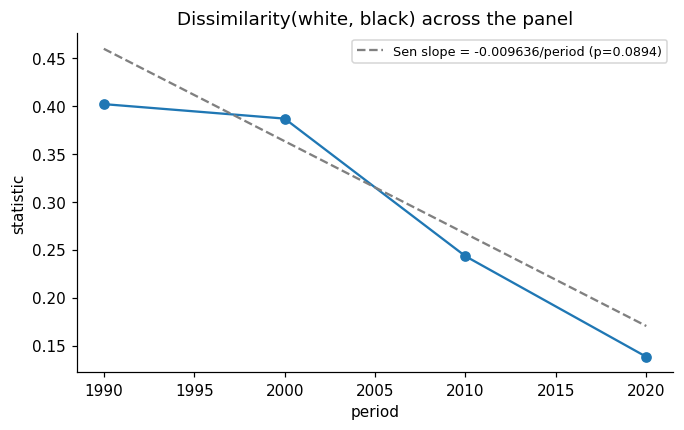

   period_from  period_to  total_change  spatial_component  \
0         1990       2000     -0.015106           0.036605   
1         2000       2010     -0.143481          -0.145091   
2         2010       2020     -0.104888          -0.107950   

   composition_component  
0              -0.051711  
1               0.001610  
2               0.003061  


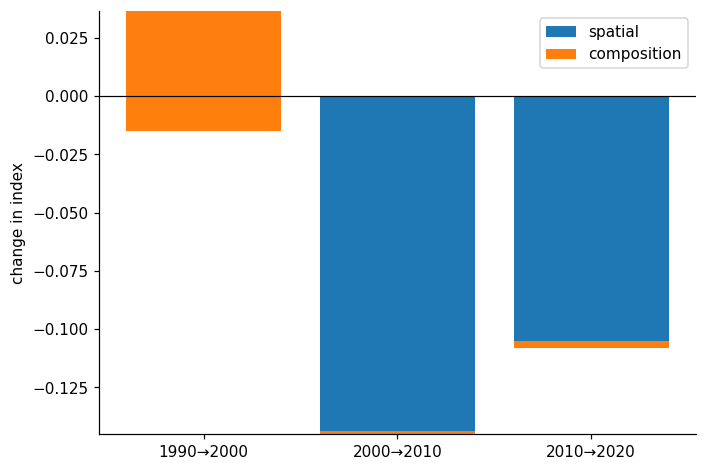

In [8]:
# ===================================================================
# Build a consistent panel, test the Mann-Kendall trend in D, and chain
# spatial-vs-composition decompositions across consecutive periods.
# ===================================================================

# Harmonized 1990 plus the three shared-boundary years.
panel_gdfs = {  # define panel_gdfs
    1990: harmonized_areal,
    2000: tracts[2000],
    2010: tracts[2010],
    2020: tracts[2020],
}

# Mann-Kendall trend on dissimilarity(white, black) across the panel.
trend_result = seg.trend(panel_gdfs, ["white", "black"], seg.dissimilarity)  # define trend_result
print(trend_result["panel"])  # run this analysis or plotting step
print(  # run this analysis or plotting step
    f"\ntrend: {trend_result['trend']}  (p={trend_result['p_value']:.4f}, "  # run this analysis or plotting step
    f"Sen slope={trend_result['sen_slope']:.5f} per period)"
)

ax = seg.plot_trend(trend_result["panel"], trend_result=trend_result)  # axes handle for drawing
ax.set_title("Dissimilarity(white, black) across the panel")  # set labels, title, or axis limits
plt.show()  # run this analysis or plotting step

# Spatial vs composition change for every consecutive pair of years.
chain = seg.chain_decomposition(panel_gdfs, ["white", "black"])  # define chain
print(chain[["period_from", "period_to", "total_change", "spatial_component", "composition_component"]])  # run this analysis or plotting step
ax2 = seg.plot_decomposition(chain)  # axes handle for drawing
plt.show()  # run this analysis or plotting step


## Exporting local segregation as a causal-package exposure variable

`report.export_for_causal` turns any local measure into a tidy, geometry-free table keyed
by unit id -- the shape `geolattice.spatial_analysis.spatialcausal` or PyCausalML's cross-sectional and panel
estimators expect for an exposure or confounder column. Merge it onto an outcome dataset
(school performance, health outcomes, ...) by tract id to use measured segregation as a
covariate rather than recomputing it inside a causal pipeline.






In [9]:
# ===================================================================
# Export the 2020 black LQ (same values as the significance map) as a
# tidy exposure table for downstream causal / regression workflows.
# ===================================================================

exposure_table = seg.export_for_causal(  # define exposure_table
    tracts[2020],
    sig["statistic"],  # reuse the significance test's LQ column
    id_col="tract_id",  # define id_col
    name="black_lq_2020",  # index name or scenario label
)
exposure_table.head()  # run this analysis or plotting step


,tract_id,black_lq_2020
0,T000,0.712410
1,T001,0.779883
2,T002,0.651717
3,T003,0.829910
4,T004,0.702614


## Summary

- Region-wide indices (`indices` / `report.compute`) summarize a city in one number per
  group pairing, with a spatially-aware bootstrap confidence interval.
- Local measures (`local`) and FDR-corrected permutation significance turn that one
  number into a LISA-style map of where segregation is concentrated.
- The multiscale profile (`multiscale`) answers *how far* that segregation reaches,
  using a KD-tree instead of a dense pairwise-distance table -- the specific scaling
  limit that motivated rewriting this instead of calling PySAL directly.
- `neighborhoods`, `data` (boundary harmonization), `temporal` (panels and trend
  tests), and `decomposition` (chained, exactly-additive spatial-vs-composition splits)
  extend every one of those ideas across space, across boundary changes, and across
  time -- the three gaps a two-values-at-a-time, unit-level-bootstrap tool cannot close.
- `report.export_for_causal` is the hook back out to `geolattice.spatial_analysis.spatialcausal` and
  PyCausalML: a measured segregation surface, ready to use as an exposure or confounder
  rather than an assumption.



